In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [2]:
df = pd.read_csv('CNORecall_v1_merged.csv')


In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


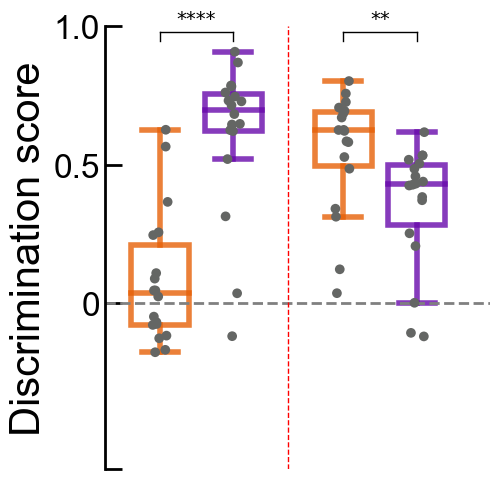

In [9]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['****','**']
colors = ["#a2a6a3","#a2a6a3"]
colors = ["#646664","#646664"]
colors_boxplot = ['#e66007', "#680aab"]

ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    size=7,
    facecolors='none',
    edgecolors='black',
    palette=colors,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)
plt.axhline(linewidth=2, color='grey',ls='--')
plt.axvline(x=0.5,linewidth=1, color='red',ls='--')


data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_linewidth(2)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i%2]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

plt.legend([],[], frameon=False)
ax.spines['left'].set_color('black')


ax.set_yticks([0,0.5,1], fontname='Arial')

ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Discrimination score', fontsize = 30, fontname='Arial')
#ax.set_ylabel('', fontsize = 26)

ax.set_yticks([-0.6,0,0.5,1], fontname='Arial')
ax.set_yticklabels(['','0','0.5','1.0'],fontname='Arial')

#ax.set_xticks([-0.2,0.2,0.8,1.2])
#ax.set_xticklabels(['Uncond.','SFC','Uncond.','SFC'],fontname='Arial', fontsize=18)

ax.set_ylim([-0.6,1])
ax.set_xlim([-0.5,1.6])

ax.set_xticks([])
ax.set_xlabel("",fontsize=20)

#ax.text(-0.35,1.1,'Recall Day 1',fontname="Arial",fontsize=20)
#ax.text(0.6,1.1,'Recall Day 2',fontname="Arial",fontsize=20)

significance(ax,0,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[0])
significance(ax,1,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[1])

#plt.title("CS- arena half", fontsize=24,y=1.05)

fig = ax.get_figure()
adjust_box_widths(fig, 0.8)
fig.set_size_inches(5.1,4.9)
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)
#plt.xticks(rotation=60, ha="right")

plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig_CA2Extinction.jpg",dpi=600,bbox_inches='tight')
plt.savefig('Fig_CA2Extinction.eps', dpi=600, format='eps')

